In [173]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [174]:
df = pd.read_csv(r"C:\Users\prodd\Downloads\archive\amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [175]:
crosstable=pd.crosstab(df["category"],df["isBestSeller"])
crosstable

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [176]:
sorted=df.groupby('category').agg({'isBestSeller':'count'}).sort_values(by='isBestSeller',ascending=False)

In [177]:
from scipy.stats import chi2_contingency
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstable)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [178]:
print("There is a statistically significant association between product category and is bestseller")

There is a statistically significant association between product category and is bestseller


In [179]:
from scipy.stats.contingency import association
association(crosstable, method="cramer")

0.1222829439760564

In [180]:
print("there is associated between product category and is bestseller but the associated strength is very weak")

there is associated between product category and is bestseller but the associated strength is very weak


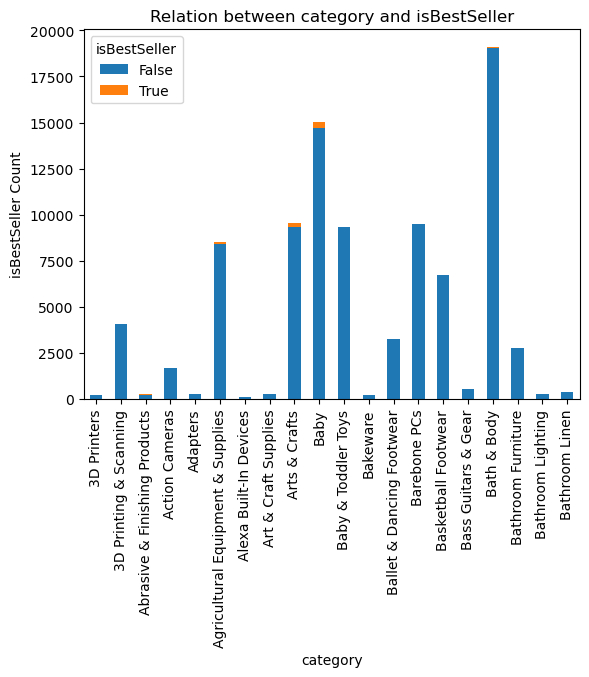

In [181]:
crosstable.head(20).plot(kind="bar", stacked=True)
plt.xlabel('category')
plt.ylabel('isBestSeller Count')
plt.title('Relation between category and isBestSeller')
plt.show()


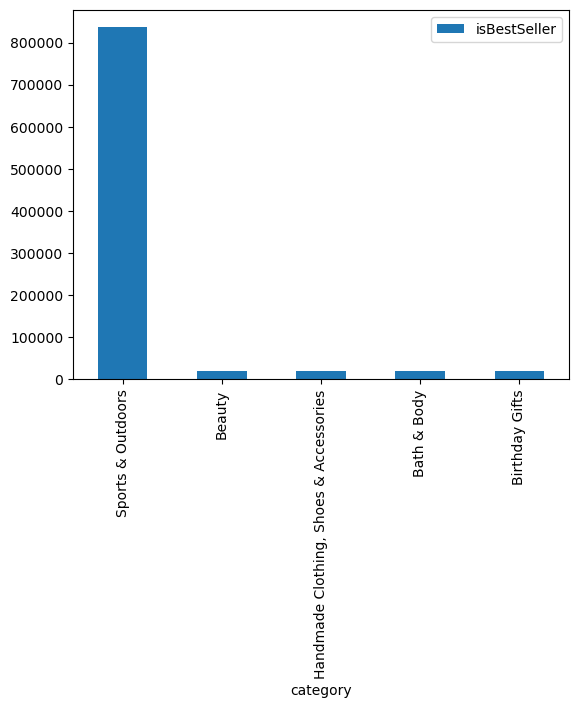

In [182]:
sorted.head(5).plot(kind="bar", stacked=True)
plt.show()

In [ ]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]


In [214]:
df_clean

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [220]:
top_20=df.groupby('category').agg({'price':'count'}).sort_values(by="price",ascending=False).head(20).index


In [226]:
df_top_20 = df_clean[df_clean['category'].isin(top_20)]


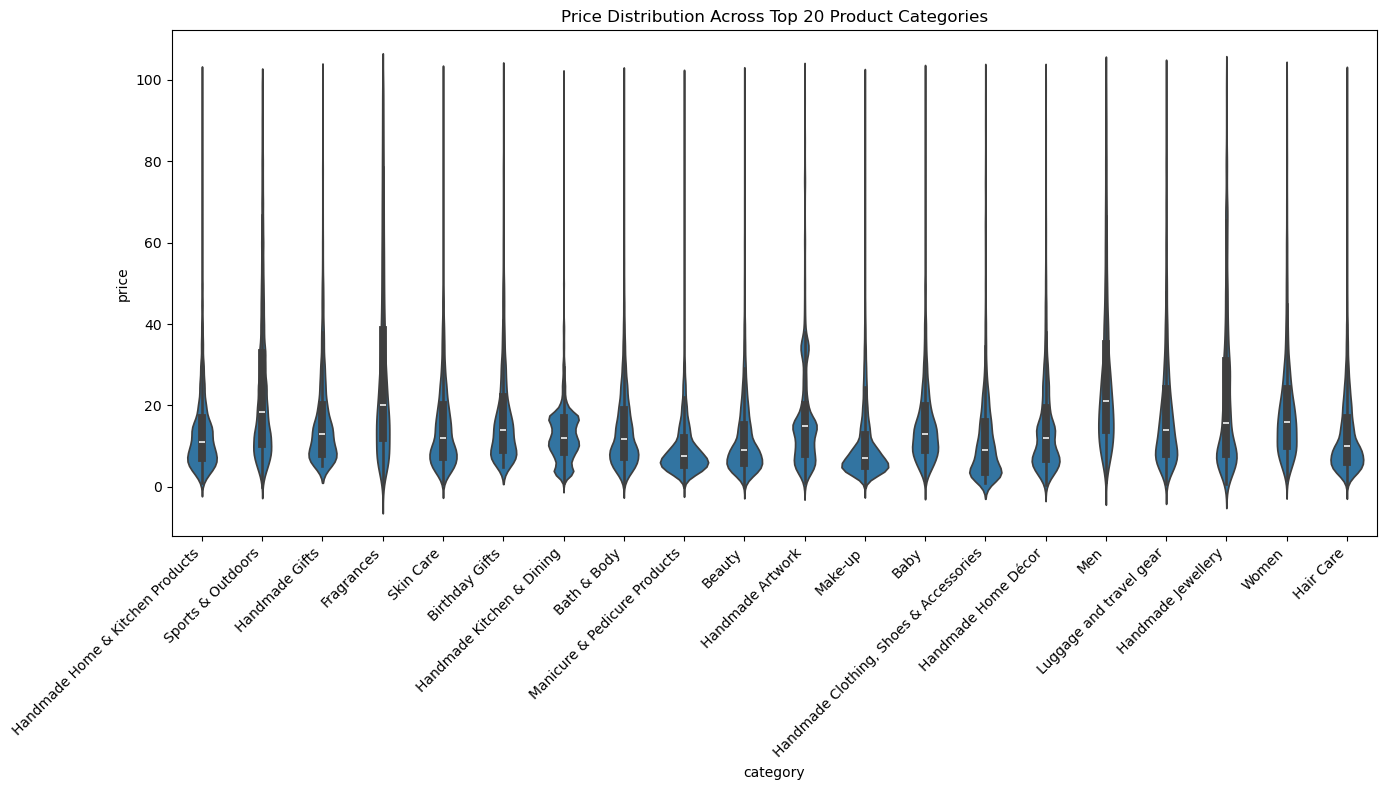

In [230]:
plt.figure(figsize=(14, 8))
sns.violinplot(x='category', y='price', data=df_top_20)
plt.xticks(rotation=45,ha="right")
plt.title('Price Distribution Across Top 20 Product Categories')
plt.tight_layout()
plt.show()


In [189]:
df.groupby('category').agg({'price':'median'}).sort_values(by="price",ascending=False).head(1)

,price
category,
Laptops,1042.725


In [249]:
top_10=df.groupby('category').agg({'price':'count'}).sort_values(by="price",ascending=False).head(10).index

In [250]:
df_top_10=df_clean[df_clean['category'].isin(top_10)]

C:\Users\prodd\AppData\Local\Temp\ipykernel_12688\4230474928.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_10, x='category', y='price', palette="coolwarm",estimator="mean")


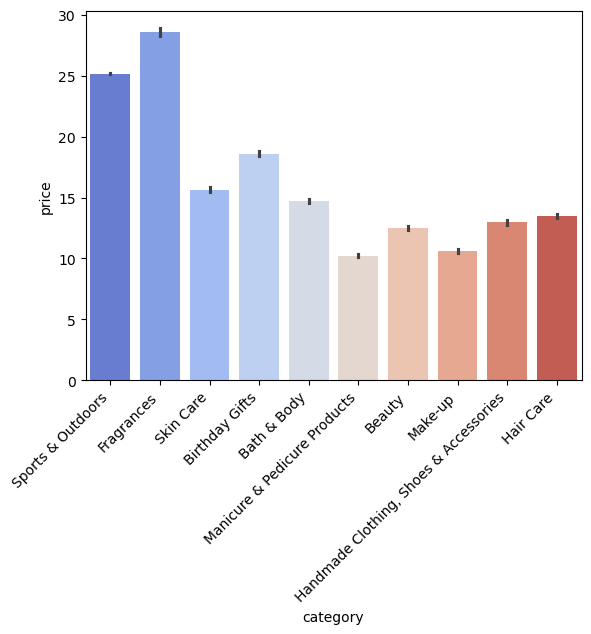

In [251]:
sns.barplot(data=df_top_10, x='category', y='price', palette="coolwarm",estimator="mean")
plt.xticks(rotation=45,ha="right")
plt.show()

In [192]:
df.groupby('category').agg({'price':'mean'}).sort_values(by="price",ascending=False).head(1)

,price
category,
Laptops,1087.987827


In [236]:
top_10c=df["category"].value_counts().head(10).index

In [237]:
df_top_10c=df_clean[df_clean['category'].isin(top_10c)]

C:\Users\prodd\AppData\Local\Temp\ipykernel_12688\3959762904.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_10c, x='category', y='stars', palette="coolwarm")


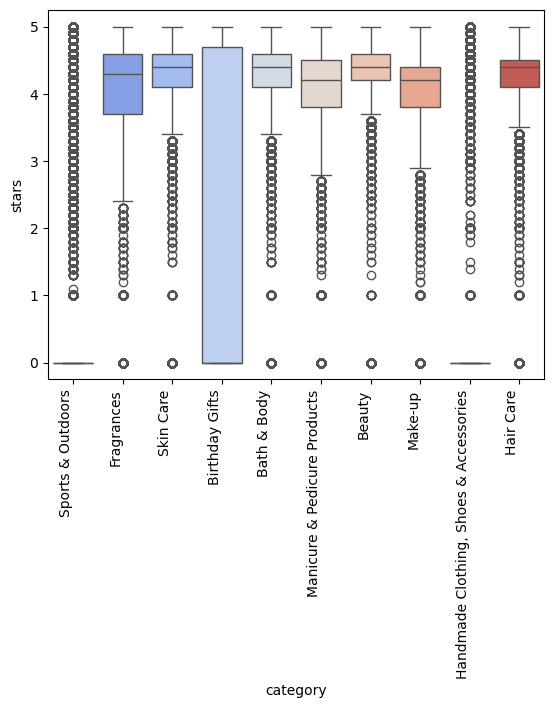

In [252]:
sns.boxplot(data=df_top_10c, x='category', y='stars', palette="coolwarm")
plt.xticks(rotation=90,ha="right")
plt.show()

In [194]:
df.groupby('category').agg({'reviews':'median'}).sort_values(by="reviews",ascending=False).head(1)

,reviews
category,
Mobile Phone Accessories,1308.0


In [195]:
df.groupby('category').agg({'stars':'median'}).sort_values(by="stars",ascending=False).head(1)

,stars
category,
Computer Memory,4.7


In [196]:
correlation_p = df['price'].corr(df['stars'])
correlation_p

np.float64(-0.12490673262148641)

In [197]:
correlation_s = df['price'].corr(df['stars'], method='spearman')
correlation_s

np.float64(-0.13316425462433912)

In [198]:
print("There is a negative linear correlation and negative monotonic correlation between price and stars.As the price increases,the stars rating decreases")

There is a negative linear correlation and negative monotonic correlation between price and stars.As the price increases,the stars rating decreases


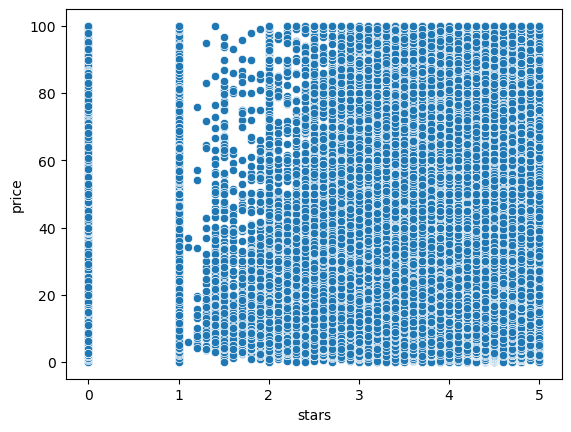

In [253]:
sns.scatterplot(data=df_clean, x='stars', y='price')
plt.show()

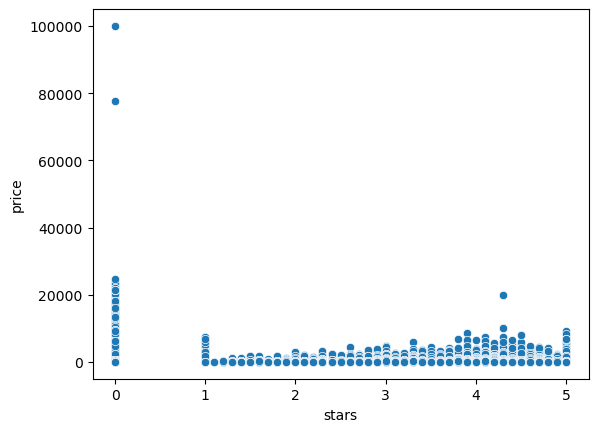

In [254]:
sns.scatterplot(data=df, x='stars', y='price')
plt.show()

In [200]:
#most of the data points are concentrated in the stars from 1 to 5 and with in the price of below 20000 most of the stars rating were given .

In [255]:
df_categorical = df_clean.select_dtypes("object")
df_numerical = df_clean.select_dtypes("number")

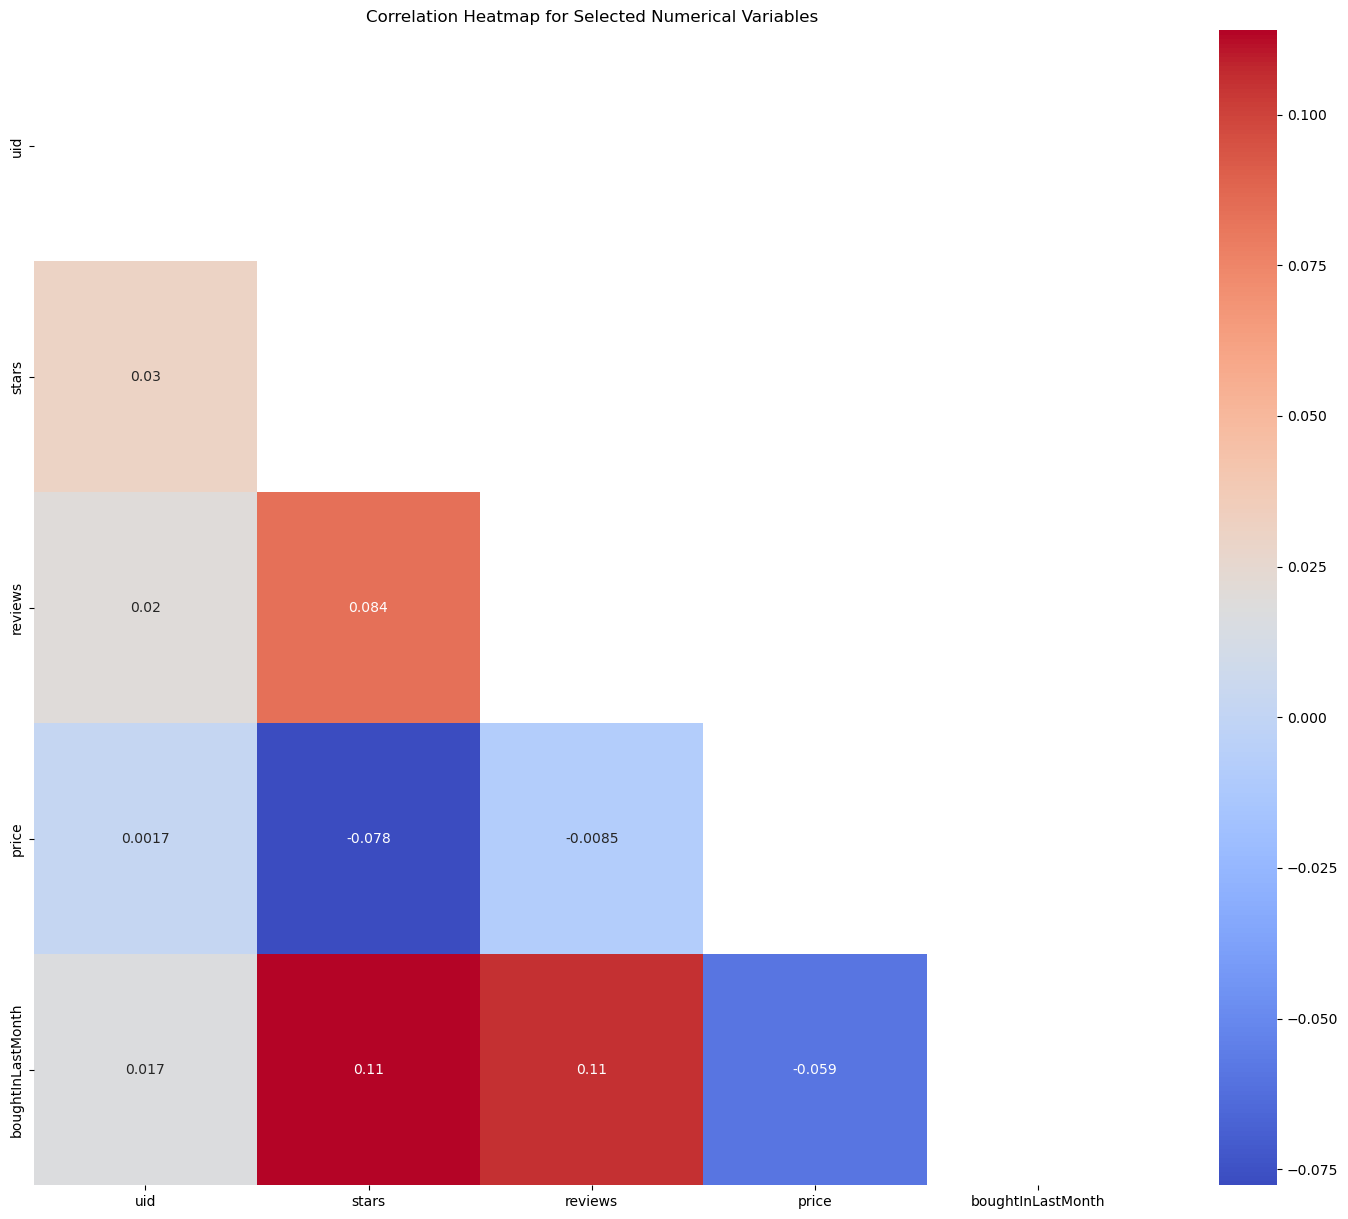

In [256]:
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

#Mask to hide upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

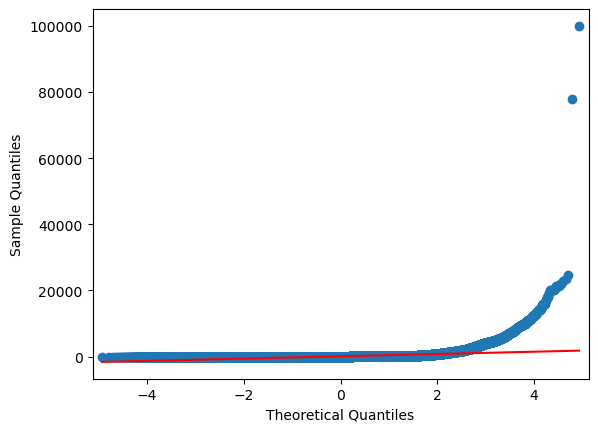

In [204]:
import statsmodels.api as sm

sm.qqplot(df['price'], line='s');
plt.show()

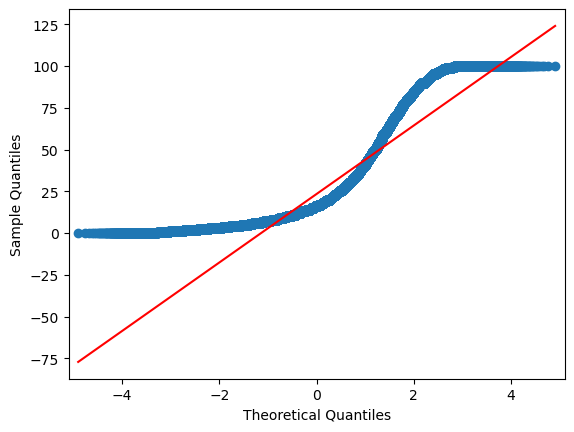

In [257]:
import statsmodels.api as sm

sm.qqplot(df_clean['price'], line='s');
plt.show()